# Statistical Moments and Time Series

This notebook accompanies the note [statistical moments and time series](../../notes/time_series/statistical_moments_and_time_series.md). In a time series, moments acquire a time index: the mean $\mu_t$ and variance may drift, and covariance becomes a function of lag $\gamma_t(h)=\mathrm{Cov}(X_t,X_{t-h})$.

We verify the worked calculations from the note, then show with simulations that

- order matters even when marginal moments are identical,
- the mean and the variance can change separately,
- rolling windows trade resolution against noise,
- cross-covariance reveals lead-lag association.

## 1. Worked calculation: mean, variance, lag-1 covariance

For the four observations $2, 4, 4, 6$ the note gives $\bar x=4$, a population-style variance of $2$ (divide by $n$), an unbiased sample variance of $8/3\approx 2.667$ (divide by $n-1$), and a lag-1 covariance of $0$. For the orderings $(1,2,4,3)$ and $(1,2,3,4)$ it gives lag-1 covariances $0.1875$ and $0.3125$ with the same marginal summaries.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

def lag_cov(x, h, ddof=0):
    x = np.asarray(x, dtype=float)
    xc = x - x.mean()
    n = len(x)
    return np.sum(xc[h:] * xc[:n - h]) / (n - ddof)

x = np.array([2, 4, 4, 6])
print("sample mean           :", x.mean())
print("variance (divide n)   :", x.var(ddof=0))
print("variance (divide n-1) :", round(x.var(ddof=1), 4), "  8/3 =", round(8/3, 4))
print("lag-1 covariance      :", lag_cov(x, 1))

for seq in ([1, 2, 4, 3], [1, 2, 3, 4]):
    s = np.array(seq)
    print(f"\nsequence {seq}: mean={s.mean()}, var={s.var():.4f}, "
          f"centered={s - s.mean()}, lag-1 cov={lag_cov(s, 1):.4f}")

sample mean           : 4.0
variance (divide n)   : 2.0
variance (divide n-1) : 2.6667   8/3 = 2.6667
lag-1 covariance      : 0.0

sequence [1, 2, 4, 3]: mean=2.5, var=1.2500, centered=[-1.5 -0.5  1.5  0.5], lag-1 cov=0.1875

sequence [1, 2, 3, 4]: mean=2.5, var=1.2500, centered=[-1.5 -0.5  0.5  1.5], lag-1 cov=0.3125


All numbers agree with the note. The last two sequences contain the same four values, so every marginal moment is identical, but their lag-1 covariances differ ($0.1875$ versus $0.3125$): temporal order carries information that marginal moments discard.

## 2. Marginal moments cannot see time order

We make the point at scale: take an AR(1) series with $\phi=0.8$ and a random permutation of the same values. The permuted series has exactly the same mean, variance, skewness, and kurtosis but no serial dependence.

AR(1)     mean=-0.1305 var= 3.0691 skew= 0.0191 excess kurt=-0.3626 lag-1 autocorr= 0.822
shuffled  mean=-0.1305 var= 3.0691 skew= 0.0191 excess kurt=-0.3626 lag-1 autocorr= 0.002


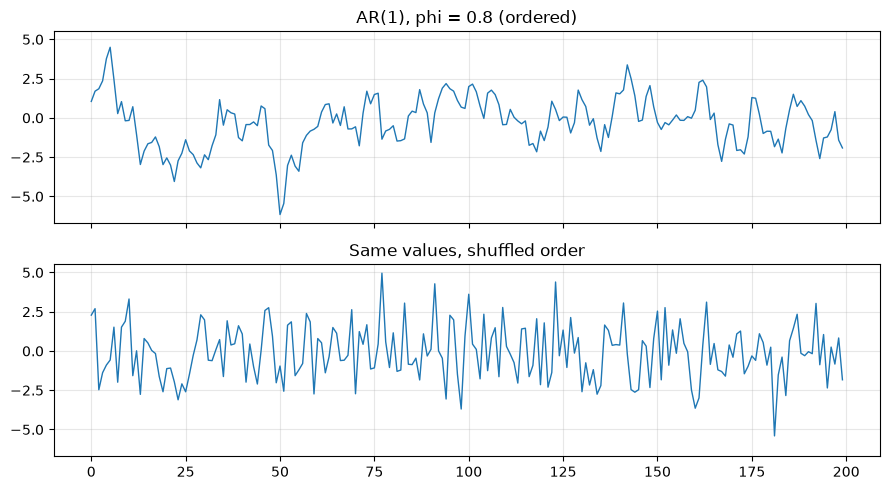

In [2]:
rng = np.random.default_rng(7)
n = 2000
eps = rng.normal(size=n + 200)
ar = np.zeros(n + 200)
for t in range(1, n + 200):
    ar[t] = 0.8 * ar[t - 1] + eps[t]
ar = ar[200:]
shuffled = rng.permutation(ar)

def summary(name, v):
    print(f"{name:9s} mean={v.mean():7.4f} var={v.var(ddof=1):7.4f} "
          f"skew={stats.skew(v):7.4f} excess kurt={stats.kurtosis(v):7.4f} "
          f"lag-1 autocorr={lag_cov(v, 1)/lag_cov(v, 0):6.3f}")

summary("AR(1)", ar)
summary("shuffled", shuffled)

fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True, sharey=True)
ax[0].plot(ar[:200], lw=1); ax[0].set_title("AR(1), phi = 0.8 (ordered)")
ax[1].plot(shuffled[:200], lw=1); ax[1].set_title("Same values, shuffled order")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The printed marginal summaries are identical, yet only the ordered series has persistent runs (lag-1 autocorrelation near $0.8$, versus about $0$ after shuffling). This is the reason a time series is not treated as an unordered sample.

## 3. A changing mean versus a changing standard deviation

The note separates two ways to violate constant moments: a series whose *location* changes with spread stable, and one whose *spread* changes with location stable. We build one of each and compare the first and second halves.

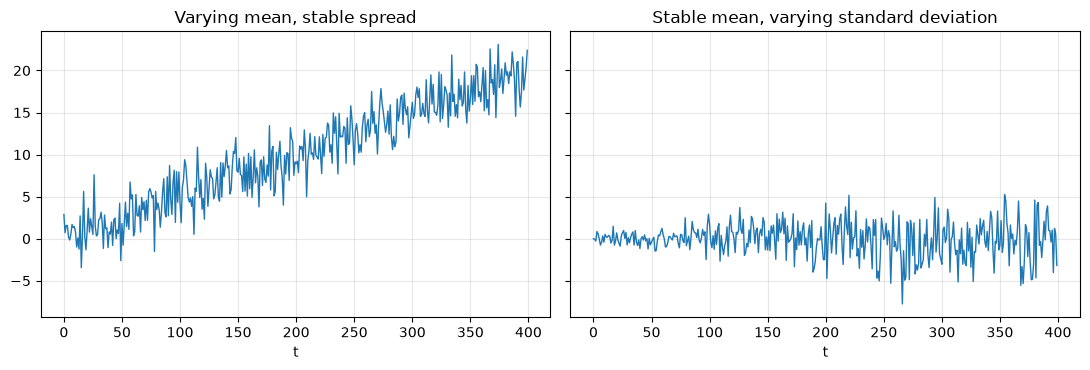

varying mean  first half: mean=  5.00 sd= 3.53 | second half: mean= 15.00 sd= 3.52
varying sd    first half: mean=  0.11 sd= 1.29 | second half: mean= -0.32 sd= 2.54


In [3]:
n = 400
t = np.arange(n)
varying_mean = 0.05 * t + rng.normal(0, 2, n)
varying_sd = rng.normal(0, 1, n) * (0.5 + 3.0 * t / n)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
ax[0].plot(varying_mean, lw=1); ax[0].set_title("Varying mean, stable spread")
ax[1].plot(varying_sd, lw=1);   ax[1].set_title("Stable mean, varying standard deviation")
for a in ax: a.grid(alpha=0.3); a.set_xlabel("t")
plt.tight_layout(); plt.show()

for name, v in (("varying mean", varying_mean), ("varying sd", varying_sd)):
    a, b = v[:n // 2], v[n // 2:]
    print(f"{name:13s} first half: mean={a.mean():6.2f} sd={a.std(ddof=1):5.2f} | "
          f"second half: mean={b.mean():6.2f} sd={b.std(ddof=1):5.2f}")

The first series changes its level but keeps roughly the same spread; the second keeps its level near zero while its spread grows several-fold. A single overall mean and variance would misdescribe both, and they violate weak stationarity in different ways.

## 4. Rolling moments and the window trade-off

With window $w$ the rolling mean and variance are

$$\hat\mu_t^{(w)}=\frac1w\sum_{j=0}^{w-1}x_{t-j},\qquad \hat v_t^{(w)}=\frac1{w-1}\sum_{j=0}^{w-1}\bigl(x_{t-j}-\hat\mu_t^{(w)}\bigr)^2 .$$

We apply windows $w=15$ and $w=80$ to the variable-spread series from the previous section.

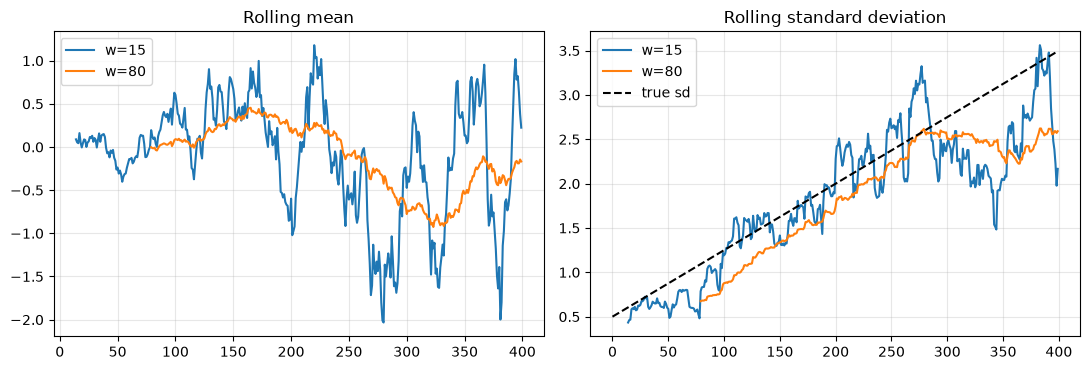

w= 15: RMSE of rolling sd vs true sd = 0.460
w= 80: RMSE of rolling sd vs true sd = 0.454


In [4]:
def rolling(x, w):
    out_m = np.full(len(x), np.nan); out_v = np.full(len(x), np.nan)
    for i in range(w - 1, len(x)):
        win = x[i - w + 1:i + 1]
        out_m[i] = win.mean(); out_v[i] = win.var(ddof=1)
    return out_m, out_v

true_sd = 0.5 + 3.0 * t / n
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for w in (15, 80):
    m, v = rolling(varying_sd, w)
    ax[0].plot(m, label=f"w={w}")
    ax[1].plot(np.sqrt(v), label=f"w={w}")
ax[1].plot(true_sd, "k--", label="true sd")
ax[0].set_title("Rolling mean"); ax[1].set_title("Rolling standard deviation")
for a in ax: a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for w in (15, 80):
    _, v = rolling(varying_sd, w)
    ok = ~np.isnan(v)
    print(f"w={w:3d}: RMSE of rolling sd vs true sd = {np.sqrt(np.mean((np.sqrt(v[ok]) - true_sd[ok])**2)):.3f}")

The short window is noisy but tracks the growing spread with little delay; the long window is smooth but lags behind. Their overall errors are similar for opposite reasons (sampling noise versus lag), so neither is "correct": the window width is a resolution choice and should be held fixed when comparing across series.

## 5. Cross-covariance and lead-lag association

The lagged cross-covariance is $\gamma_{XY}(h)=\mathrm{Cov}(X_t,Y_{t-h})$. If $Y$ drives $X$ with a delay of 3 steps, $X_t = 0.9\,Y_{t-3}+\text{noise}$, the cross-covariance should peak at $h=3$. The note warns that such a peak does not establish causality and is sensitive to trends and common seasonality.

peak at lag h = 3  value 0.901  (theory 0.9)


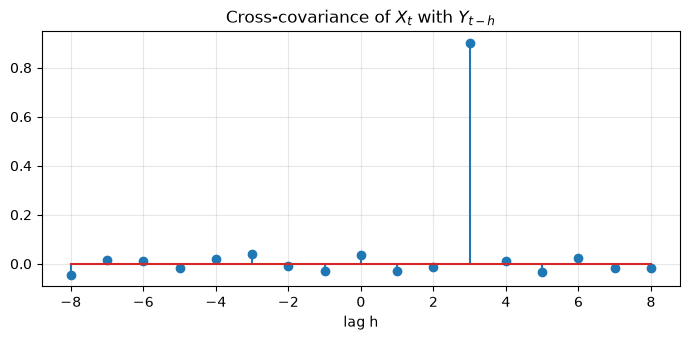

In [5]:
n = 1000
y = rng.normal(size=n)
xs = np.zeros(n)
xs[3:] = 0.9 * y[:-3]
xs += rng.normal(0, 0.5, n)

def cross_cov(x, y, h):
    xc, yc = x - x.mean(), y - y.mean()
    n = len(x)
    if h >= 0:
        return np.sum(xc[h:] * yc[:n - h]) / n
    return np.sum(xc[:n + h] * yc[-h:]) / n

hs = np.arange(-8, 9)
cc = np.array([cross_cov(xs, y, h) for h in hs])
print("peak at lag h =", hs[np.argmax(cc)], " value", round(cc.max(), 3), " (theory 0.9)")

plt.figure(figsize=(7, 3.5))
plt.stem(hs, cc)
plt.xlabel("lag h"); plt.title(r"Cross-covariance of $X_t$ with $Y_{t-h}$")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

The cross-covariance is essentially zero at every lag except $h=3$, where it is close to the theoretical $0.9\,\mathrm{Var}(Y)=0.9$. This recovers the built-in delay, but remember it is a statement about linear association and timing, not about causal mechanism.

**Takeaways.** Moments must be read together with their time and lag structure: identical marginal moments can hide different dependence, mean and variance can drift independently, and rolling summaries are descriptive tools whose window size is a modeling choice.